In [ ]:
import os
import pandas as pd
import urllib.request
import zipfile
from google.colab import drive

# ==========================================
# STEP 1: Mount Google Drive
# ==========================================
# drive.mount('/content/drive')
project_dir = '/content/drive/MyDrive/BTech_Bivariate_Joint_Model/DataSet'
os.makedirs(project_dir, exist_ok=True)
os.chdir(project_dir)


In [ ]:

# ==========================================
# STEP 2: Download the Main Zip
# ==========================================
url = "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip"
main_zip_path = os.path.join(project_dir, "CMAPSS_Main.zip")

if not os.path.exists(main_zip_path):
    print("Downloading C-MAPSS dataset...")
    urllib.request.urlretrieve(url, main_zip_path)
else:
    print("Main zip already exists. Skipping download.")

# ==========================================
# STEP 3: Recursive Extraction (The Fix)
# ==========================================
print("Extracting main zip file...")
with zipfile.ZipFile(main_zip_path, 'r') as zip_ref:
    zip_ref.extractall(project_dir)

# Scan for any nested zip files that NASA hid inside the main folder
for root, dirs, files in os.walk(project_dir):
    for file in files:
        if file.endswith('.zip') and file != "CMAPSS_Main.zip":
            nested_zip_path = os.path.join(root, file)
            print(f"Found nested zip: {file}! Extracting it now...")

            with zipfile.ZipFile(nested_zip_path, 'r') as nested_zip_ref:
                nested_zip_ref.extractall(root)

            # Delete the nested zip after extracting so it doesn't clutter your drive
            os.remove(nested_zip_path)

print("All files fully extracted!")

# ==========================================
# STEP 4: Smart Search for the Text File
# ==========================================
target_file = 'train_FD001.txt'
file_path = None

for root, dirs, files in os.walk(project_dir):
    if target_file in files:
        file_path = os.path.join(root, target_file)
        break

# ==========================================
# STEP 5: Format Data
# ==========================================
if file_path is None:
    print(f"\n❌ ERROR: Still could not find {target_file}.")
else:
    print(f"\n✅ Found data file at: {file_path}")

    # Define columns
    columns = ['Device_ID', 'Time_Cycle', 'Op_Setting_1', 'Op_Setting_2', 'Op_Setting_3'] + \
              [f'Sensor_{i}' for i in range(1, 22)]

    # Create the DataFrame
    df = pd.read_csv(file_path, sep=r'\s+', header=None, names=columns)

    # Add Survival Event Indicator
    df['Event_0_1'] = 0
    max_cycles = df.groupby('Device_ID')['Time_Cycle'].max()

    for engine_id, max_time in max_cycles.items():
        df.loc[(df['Device_ID'] == engine_id) & (df['Time_Cycle'] == max_time), 'Event_0_1'] = 1

    print("✅ Data formatted successfully! Here are the final 5 cycles of Engine 1:")
    display(df[df['Device_ID'] == 1].tail())

Extracting main zip file...
Found nested zip: CMAPSSData.zip! Extracting it now...
All files fully extracted!

✅ Found data file at: /content/drive/MyDrive/BTech_Bivariate_Joint_Model/DataSet/6. Turbofan Engine Degradation Simulation Data Set/train_FD001.txt
✅ Data formatted successfully! Here are the final 5 cycles of Engine 1:


,Device_ID,Time_Cycle,Op_Setting_1,Op_Setting_2,Op_Setting_3,Sensor_1,Sensor_2,Sensor_3,Sensor_4,Sensor_5,...,Sensor_13,Sensor_14,Sensor_15,Sensor_16,Sensor_17,Sensor_18,Sensor_19,Sensor_20,Sensor_21,Event_0_1
187,1,188,-0.0067,0.0003,100.0,518.67,643.75,1602.38,1422.78,14.62,...,2388.23,8117.69,8.5207,0.03,396,2388,100.0,38.51,22.9588,0
188,1,189,-0.0006,0.0002,100.0,518.67,644.18,1596.17,1428.01,14.62,...,2388.33,8117.51,8.5183,0.03,395,2388,100.0,38.48,23.1127,0
189,1,190,-0.0027,0.0001,100.0,518.67,643.64,1599.22,1425.95,14.62,...,2388.35,8112.58,8.5223,0.03,398,2388,100.0,38.49,23.0675,0
190,1,191,-0.0000,-0.0004,100.0,518.67,643.34,1602.36,1425.77,14.62,...,2388.30,8114.61,8.5174,0.03,394,2388,100.0,38.45,23.1295,0
191,1,192,0.0009,-0.0000,100.0,518.67,643.54,1601.41,1427.20,14.62,...,2388.32,8110.93,8.5113,0.03,396,2388,100.0,38.48,22.9649,1


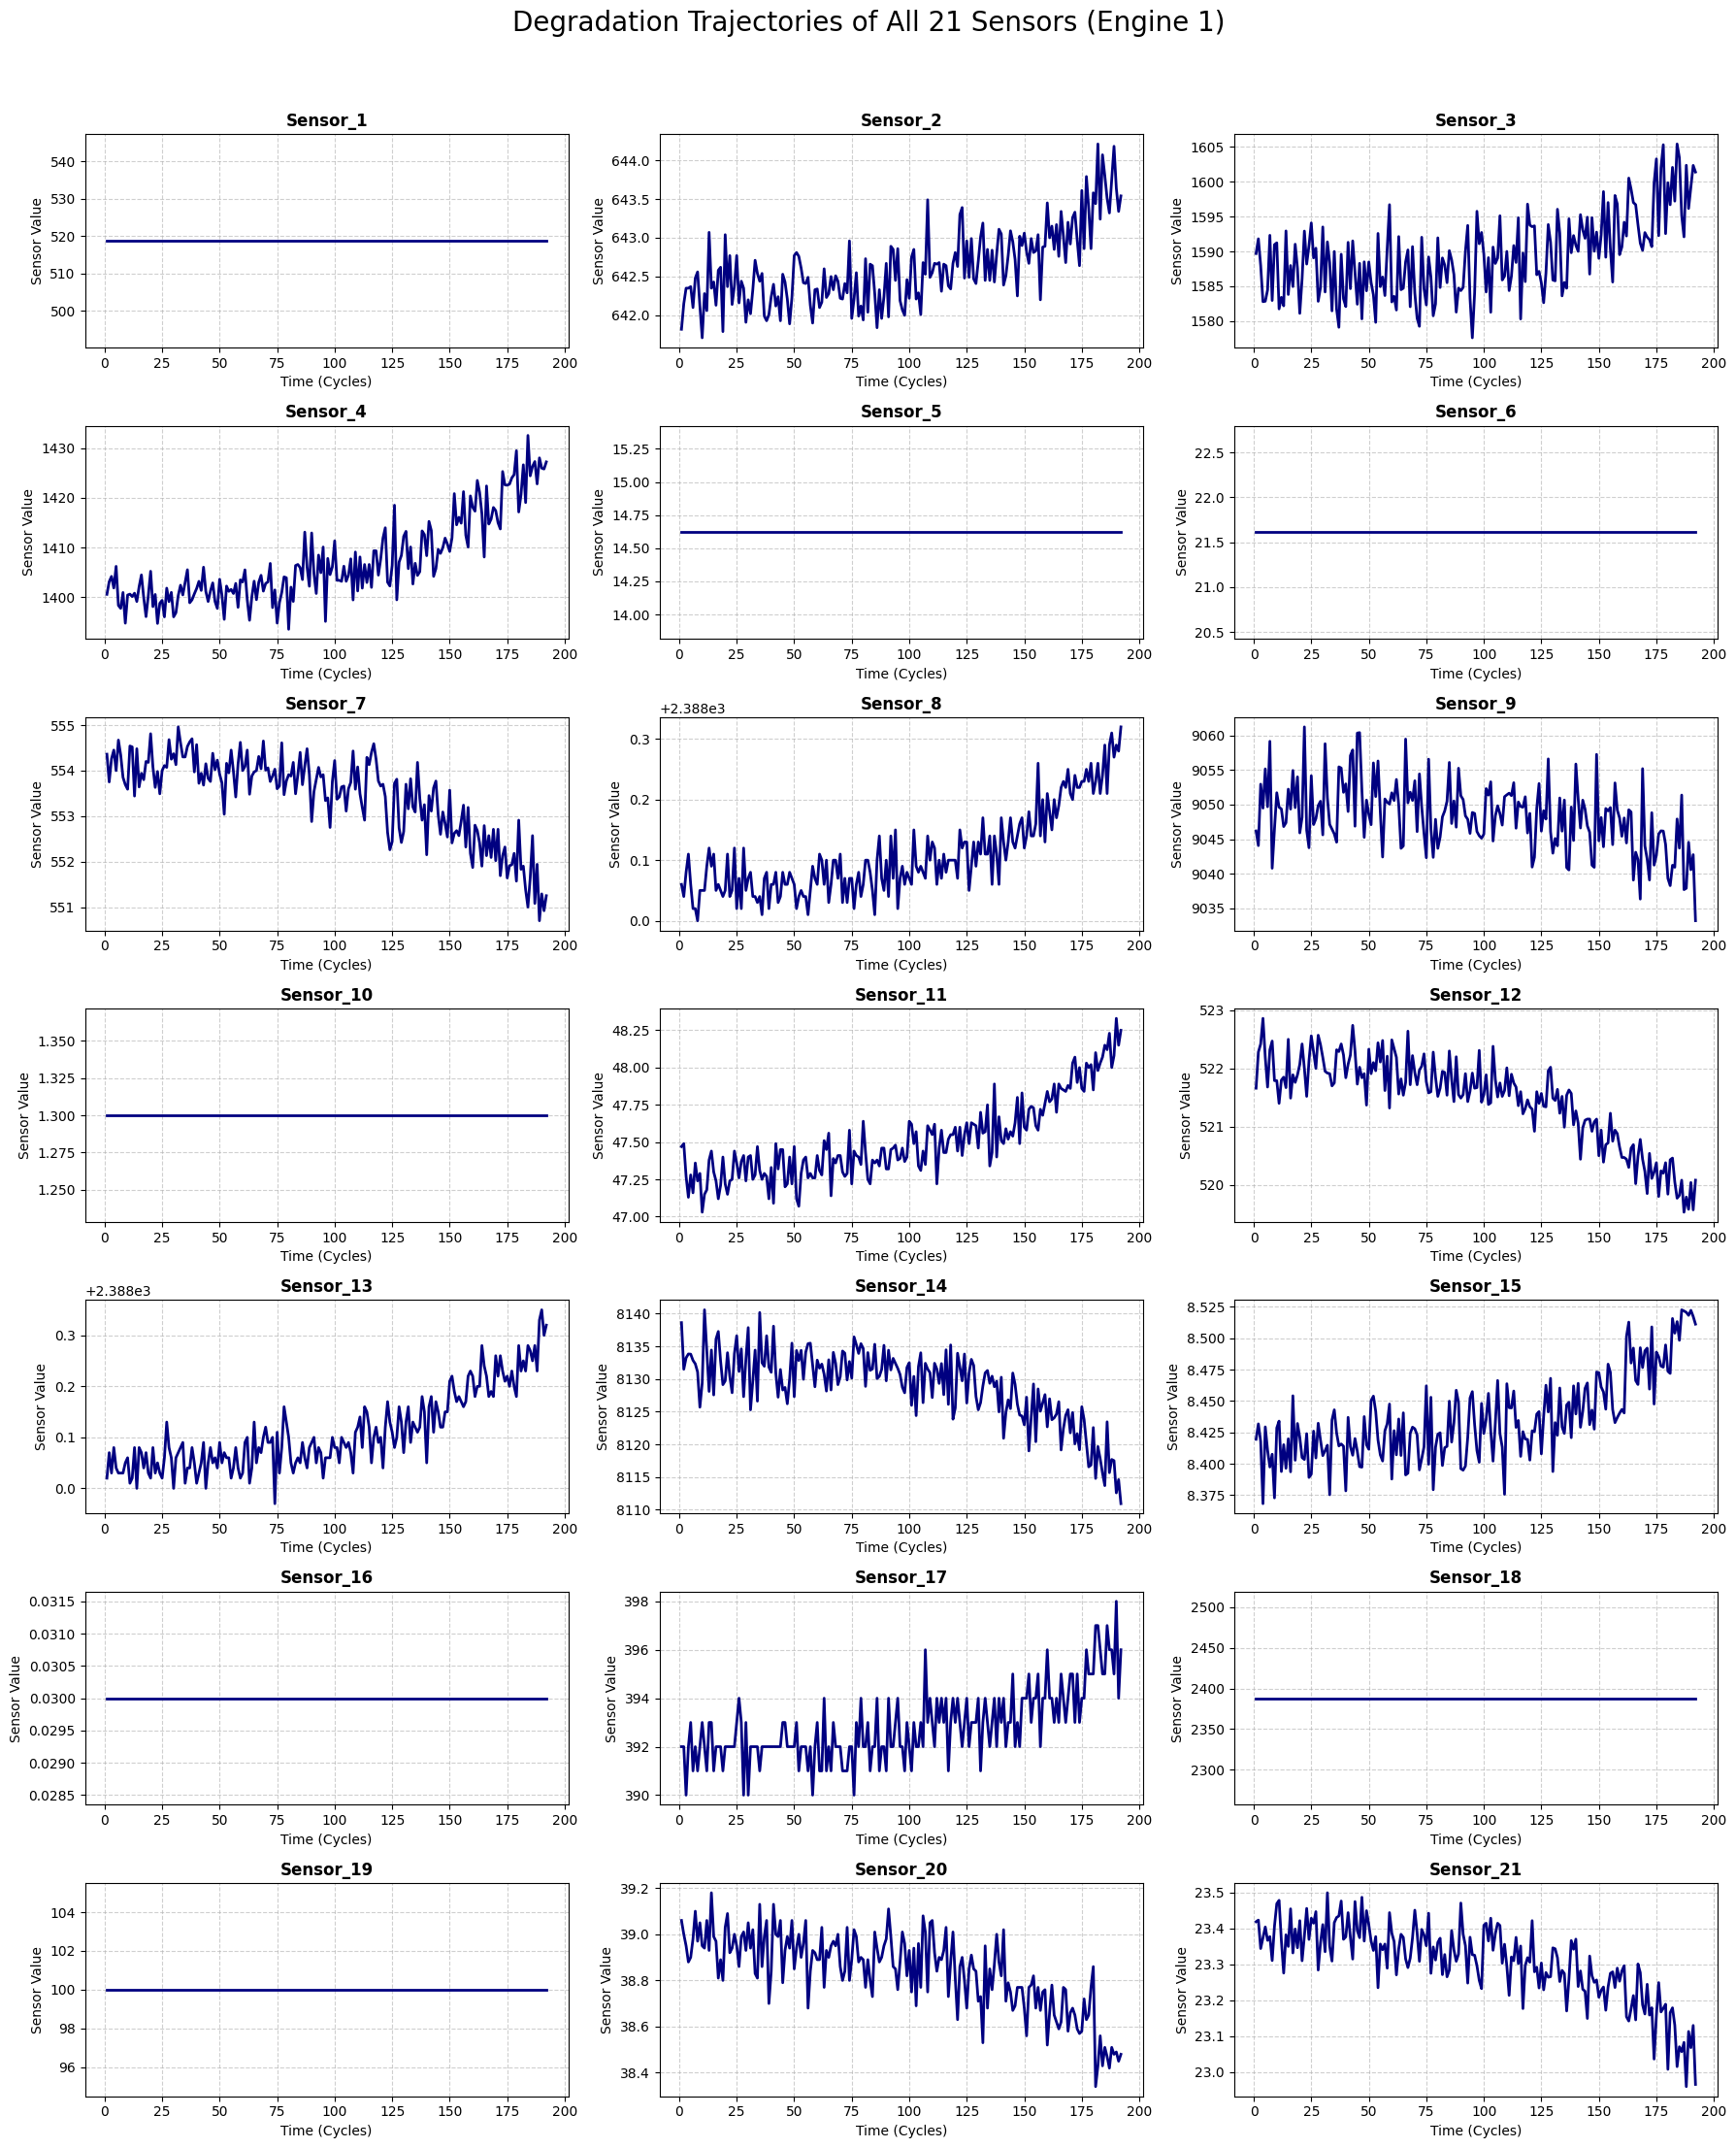


Generating Correlation Matrix for all sensors across all engines...


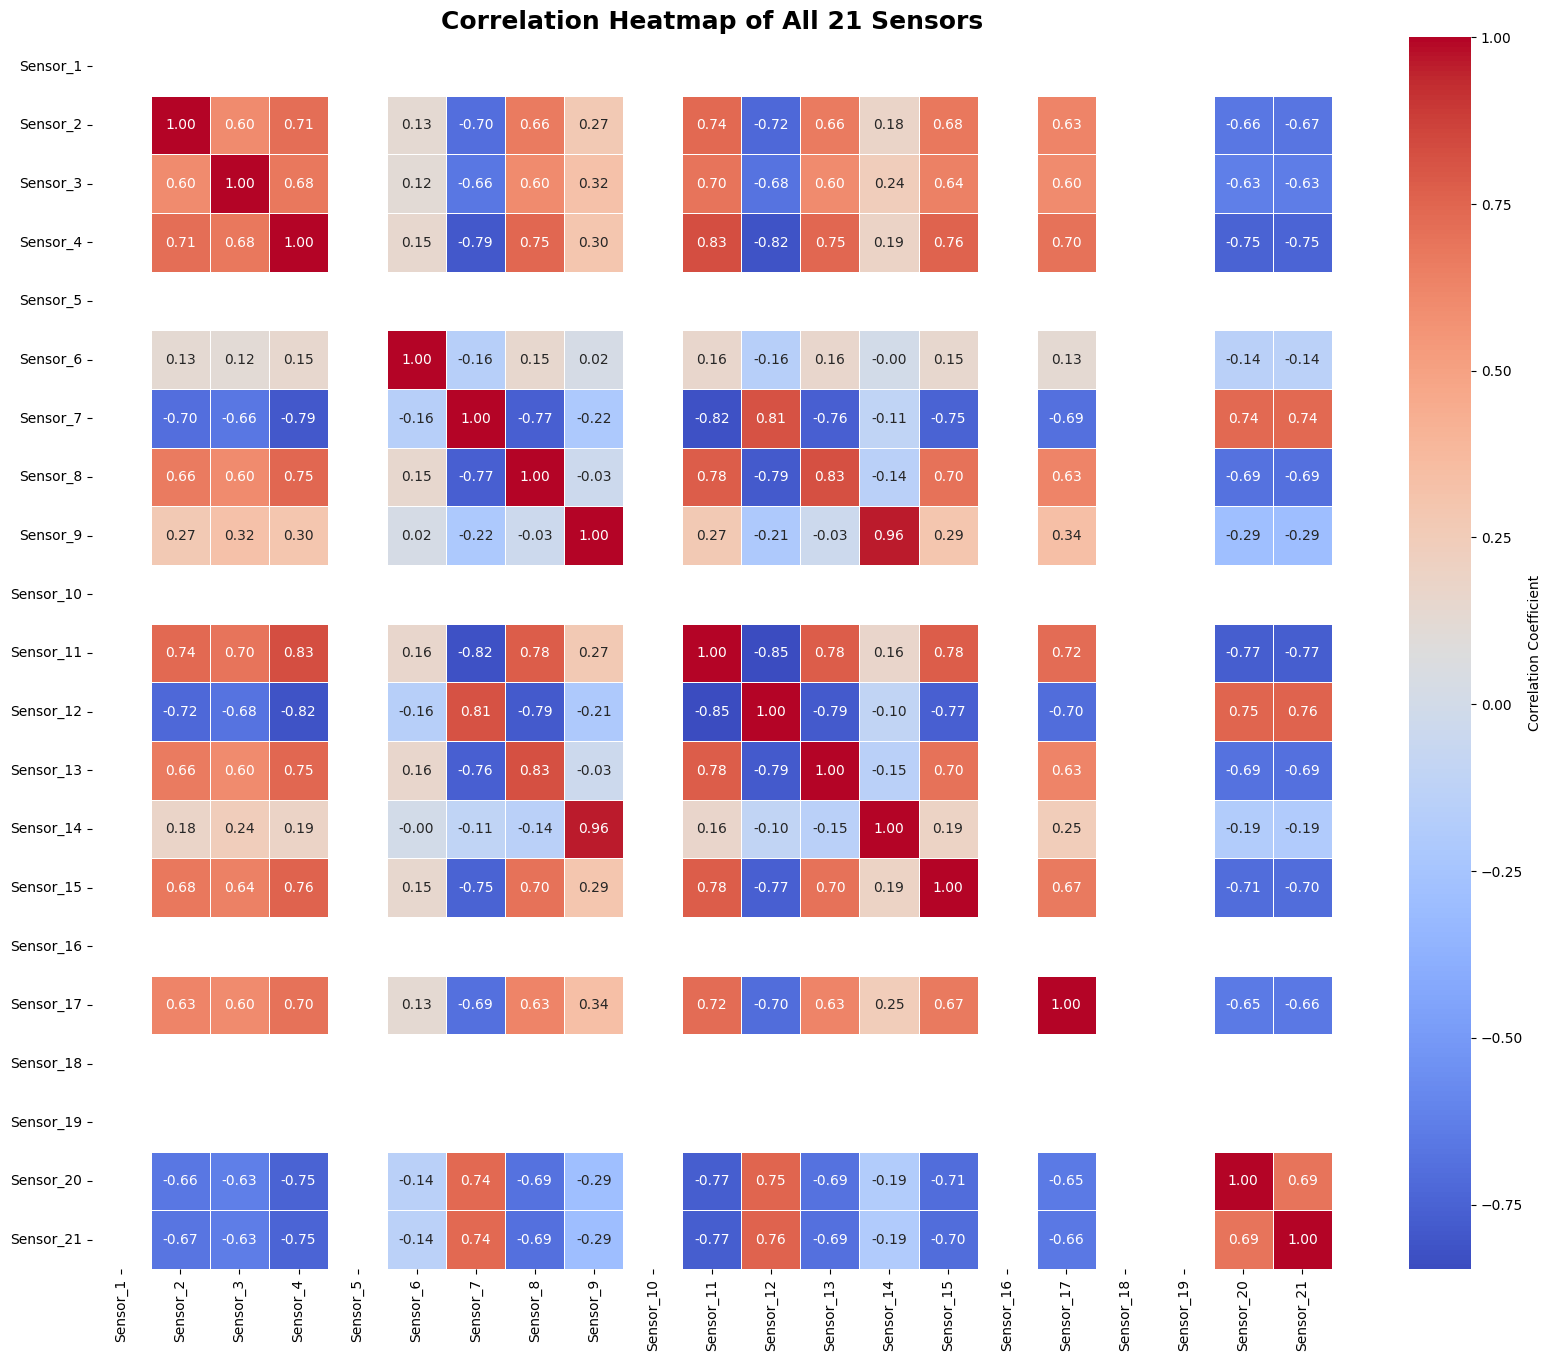

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# STEP 1: The Visual Monotonicity Check
# ==========================================
# Filter data exclusively for Engine 1
engine_1_df = df[df['Device_ID'] == 1]
sensor_cols = [f'Sensor_{i}' for i in range(1, 22)]

# Set up a 7x3 grid of plots
fig, axes = plt.subplots(7, 3, figsize=(18, 24))
fig.suptitle('Degradation Trajectories of All 21 Sensors (Engine 1)', fontsize=20, y=0.92)
axes = axes.flatten()

# Loop through and plot each sensor
for i, col in enumerate(sensor_cols):
    axes[i].plot(engine_1_df['Time_Cycle'], engine_1_df[col], color='navy', linewidth=2)
    axes[i].set_title(col, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Time (Cycles)')
    axes[i].set_ylabel('Sensor Value')
    axes[i].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

# ==========================================
# STEP 2: The Covariance/Correlation Trap Check
# ==========================================
print("\nGenerating Correlation Matrix for all sensors across all engines...")

# Calculate the correlation matrix using the entire training dataframe
plt.figure(figsize=(20, 16))
correlation_matrix = df[sensor_cols].corr()

# Plot the heatmap
sns.heatmap(correlation_matrix,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=0.5,
            cbar_kws={'label': 'Correlation Coefficient'})

plt.title('Correlation Heatmap of All 21 Sensors', fontsize=18, fontweight='bold')
plt.show()

Generating Cleaned Correlation Matrix for surviving sensors...


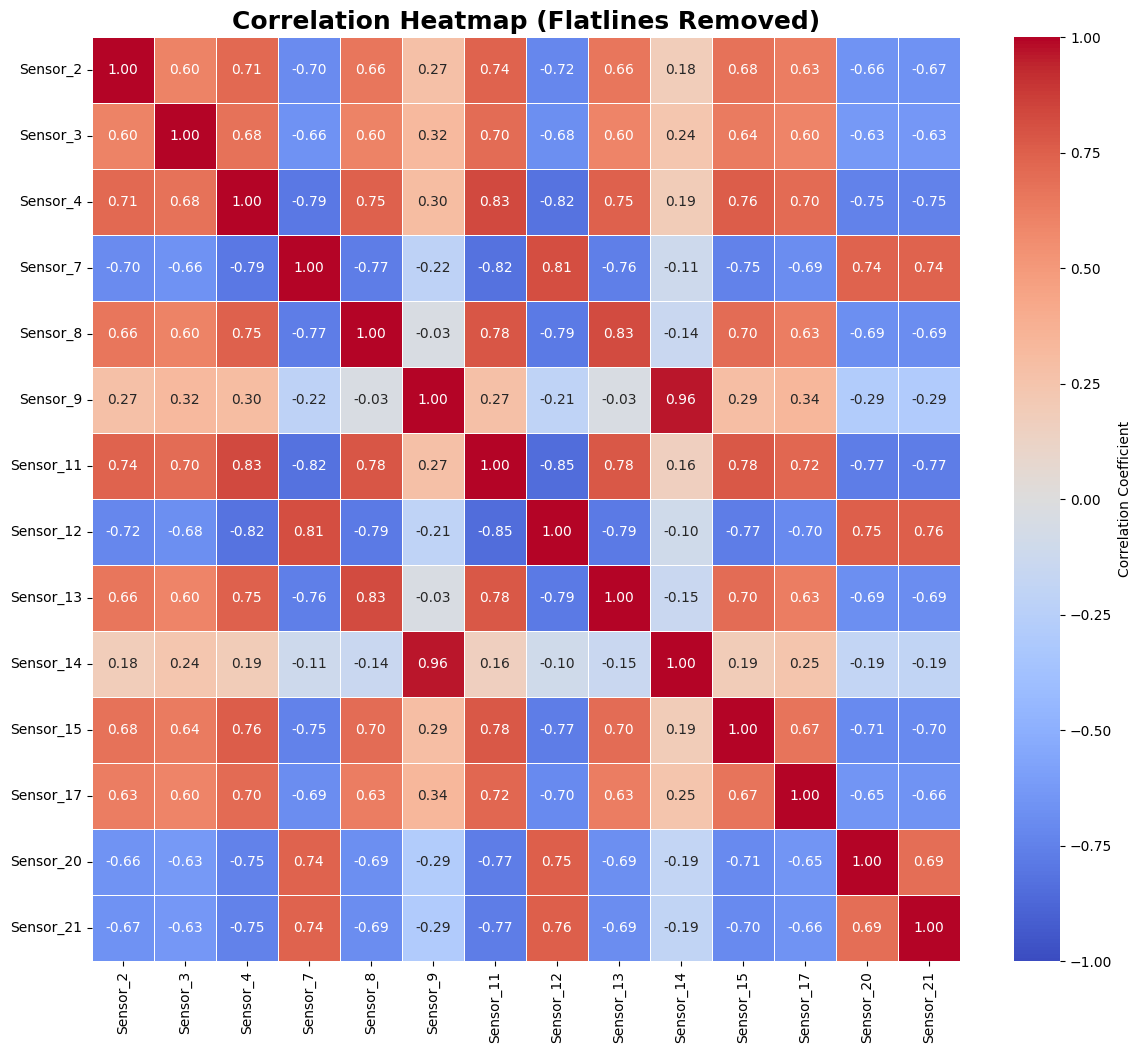

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Define our surviving, trending sensors (removing the flatlines)
useful_sensors = [
    'Sensor_2', 'Sensor_3', 'Sensor_4', 'Sensor_7', 'Sensor_8',
    'Sensor_9', 'Sensor_11', 'Sensor_12', 'Sensor_13', 'Sensor_14',
    'Sensor_15', 'Sensor_17', 'Sensor_20', 'Sensor_21'
]

print("Generating Cleaned Correlation Matrix for surviving sensors...")

# Calculate the correlation matrix using ONLY the useful sensors across the entire training dataset
plt.figure(figsize=(14, 12))
cleaned_corr_matrix = df[useful_sensors].corr()

# Plot the heatmap
sns.heatmap(cleaned_corr_matrix,
            annot=True,
            cmap='coolwarm',
            fmt='.2f',
            linewidths=0.5,
            vmin=-1, vmax=1, # Locks the color scale so it's consistent
            cbar_kws={'label': 'Correlation Coefficient'})

plt.title('Correlation Heatmap (Flatlines Removed)', fontsize=18, fontweight='bold')
plt.show()

In [ ]:
!pip install lifelines

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 6.0 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=8ece51293cd957d1b3a81966d7528d14ea13ce7e15706a1c435ce35e50443708
  Stored in directory: /root/.cache/pip/wheels/7e/16/46/9477f188924292d3bf1fb8fb42844201591abfc19b7ba6d868
Successfully built autograd-gamma


In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
from lifelines import CoxTimeVaryingFitter
import warnings
warnings.filterwarnings('ignore')

# =====================================================================
# SECTION 1: SETUP & DATA FILTERING FOR SELECTED SENSORS
# =====================================================================
# Selected Bivariate Pair: Sensor 7 and Sensor 3
sensor_a = 'Sensor_7'
sensor_b = 'Sensor_3'
selected_sensors = [sensor_a, sensor_b]

# Create a clean training copy
train_df = df[['Device_ID', 'Time_Cycle', sensor_a, sensor_b, 'Event_0_1']].copy()

# Min-Max Normalization per sensor to put both on a standard 0-1 scale
train_min = {}
train_max = {}

for s in selected_sensors:
    train_min[s] = train_df[s].min()
    train_max[s] = train_df[s].max()

    train_df[s] = (train_df[s] - train_min[s]) / (train_max[s] - train_min[s])


engine_ids = train_df['Device_ID'].unique()
N_engines = len(engine_ids)

# =====================================================================
# SECTION 2: STEP 1 - OFFLINE DEGRADATION PARAMETER ESTIMATION (PER ENGINE)
# =====================================================================
# Assumes K=1 change point (2 degradation phases: s=1 Normal wear, s=2 Accelerated degradation)

def build_design_matrix(time_array):
    """Constructs linear polynomial design matrix X(t) = [1, t]."""
    return np.column_stack((np.ones(len(time_array)), time_array))

def fit_ols(X, y):
    """Computes Ordinary Least Squares: beta = (X^T X)^(-1) X^T y."""
    beta = np.linalg.pinv(X.T @ X) @ X.T @ y
    residuals = y - X @ beta
    return beta, residuals

def compute_bic(residuals_matrix, T_len, n_params=7):
    """Computes BIC for candidate change point model."""
    # Sum of squared errors across both sensors
    sse = np.sum(residuals_matrix ** 2)
    variance_est = sse / (2 * T_len)
    if variance_est <= 0:
        variance_est = 1e-6
    log_likelihood = - (T_len) * np.log(2 * np.pi * variance_est) - (sse / (2 * variance_est))
    bic = n_params * np.log(T_len) - 2 * log_likelihood
    return bic

engine_records = []

for engine_id in engine_ids:
    sub = train_df[train_df['Device_ID'] == engine_id].sort_values('Time_Cycle')
    t_vals = sub['Time_Cycle'].values
    y_a = sub[sensor_a].values
    y_b = sub[sensor_b].values
    T_i = len(t_vals)

    best_bic = np.inf
    best_cp = int(T_i * 0.6) # Fallback

    # Grid Search for Change Point c_i (between 20% and 80% of total life)
    search_range = range(max(5, int(T_i * 0.2)), min(T_i - 5, int(T_i * 0.8)))

    for cp in search_range:
        # Phase 1: t <= cp
        X1 = build_design_matrix(t_vals[:cp])
        beta_a1, res_a1 = fit_ols(X1, y_a[:cp])
        beta_b1, res_b1 = fit_ols(X1, y_b[:cp])

        # Phase 2: t > cp
        X2 = build_design_matrix(t_vals[cp:])
        beta_a2, res_a2 = fit_ols(X2, y_a[cp:])
        beta_b2, res_b2 = fit_ols(X2, y_b[cp:])

        res_matrix = np.column_stack((np.concatenate([res_a1, res_a2]),
                                      np.concatenate([res_b1, res_b2])))

        score = compute_bic(res_matrix, T_i)
        if score < best_bic:
            best_bic = score
            best_cp = cp

    # Final parameter estimation with the optimal change point
    X1_opt = build_design_matrix(t_vals[:best_cp])
    beta_a1_opt, res_a1_opt = fit_ols(X1_opt, y_a[:best_cp])
    beta_b1_opt, res_b1_opt = fit_ols(X1_opt, y_b[:best_cp])

    X2_opt = build_design_matrix(t_vals[best_cp:])
    beta_a2_opt, res_a2_opt = fit_ols(X2_opt, y_a[best_cp:])
    beta_b2_opt, res_b2_opt = fit_ols(X2_opt, y_b[best_cp:])

    # 2x2 Noise Covariance Matrix per phase
    cov_phase1 = np.cov(np.column_stack((res_a1_opt, res_b1_opt)).T)
    cov_phase2 = np.cov(np.column_stack((res_a2_opt, res_b2_opt)).T)

    # Calculate fitted true degradation trajectories r_hat
    r_a = np.concatenate([X1_opt @ beta_a1_opt, X2_opt @ beta_a2_opt])
    r_b = np.concatenate([X1_opt @ beta_b1_opt, X2_opt @ beta_b2_opt])

    engine_records.append({
        'Device_ID': engine_id,
        'Change_Point': best_cp,
        'Duration_P1': best_cp,
        'Duration_P2': T_i - best_cp,
        'Beta_P1': np.hstack([beta_a1_opt, beta_b1_opt]),
        'Beta_P2': np.hstack([beta_a2_opt, beta_b2_opt]),
        'Cov_P1': cov_phase1,
        'Cov_P2': cov_phase2,
        'Time_Cycle': t_vals,
        'r_Sensor_7': r_a,
        'r_Sensor_3': r_b,
        'Failure_Time': T_i
    })

# =====================================================================
# SECTION 3: POPULATION HYPERPARAMETER AGGREGATION (PRIORS)
# =====================================================================
# Mean & Variance of Phase Durations: delta^(s) ~ N(delta_0^(s), sigma_0^(s)^2)
durations_p1 = [rec['Duration_P1'] for rec in engine_records]
durations_p2 = [rec['Duration_P2'] for rec in engine_records]

delta_0_p1, sigma_0_sq_p1 = np.mean(durations_p1), np.var(durations_p1, ddof=1)
delta_0_p2, sigma_0_sq_p2 = np.mean(durations_p2), np.var(durations_p2, ddof=1)

# Mean Vector & Covariance Matrix of Beta: beta^(s) ~ N(mu_0^(s), Sigma_0^(s))
betas_p1 = np.array([rec['Beta_P1'] for rec in engine_records])
betas_p2 = np.array([rec['Beta_P2'] for rec in engine_records])

mu_0_p1, Sigma_0_p1 = np.mean(betas_p1, axis=0), np.cov(betas_p1.T)
mu_0_p2, Sigma_0_p2 = np.mean(betas_p2, axis=0), np.cov(betas_p2.T)

# Fleet Average Measurement Error Covariance Matrices
avg_noise_cov_p1 = np.mean(np.array([rec['Cov_P1'] for rec in engine_records]), axis=0)
avg_noise_cov_p2 = np.mean(np.array([rec['Cov_P2'] for rec in engine_records]), axis=0)

print("="*60)
print("✅ OFFLINE POPULATION HYPERPARAMETERS ESTIMATED")
print("="*60)
print(f"Phase 1 Duration Mean (delta_0_p1): {delta_0_p1:.2f}, Variance: {sigma_0_sq_p1:.2f}")
print(f"Phase 2 Duration Mean (delta_0_p2): {delta_0_p2:.2f}, Variance: {sigma_0_sq_p2:.2f}")
print(f"Average Noise Covariance Phase 1:\n{avg_noise_cov_p1}")
print(f"Average Noise Covariance Phase 2:\n{avg_noise_cov_p2}")

# =====================================================================
# SECTION 4: STEP 2 - BIVARIATE TIME-VARYING COX MODEL (SURVIVAL FIT)
# =====================================================================
# Construct longitudinal time-varying dataframe using fitted r_1(t) and r_2(t)
longitudinal_rows = []

for rec in engine_records:
    dev_id = rec['Device_ID']
    times = rec['Time_Cycle']
    r_s7 = rec['r_Sensor_7']
    r_s3 = rec['r_Sensor_3']
    max_t = rec['Failure_Time']

    for k in range(len(times)):
        t_start = times[k] - 1
        t_stop = times[k]
        event = 1 if (t_stop == max_t) else 0

        longitudinal_rows.append({
            'Device_ID': dev_id,
            'start': t_start,
            'stop': t_stop,
            'r_Sensor_7': r_s7[k],
            'r_Sensor_3': r_s3[k],
            'Event': event
        })

cox_df = pd.DataFrame(longitudinal_rows)

# Fit Cox Time-Varying Model to find alpha_1 and alpha_2 weights
ctv = CoxTimeVaryingFitter()
ctv.fit(cox_df, id_col='Device_ID', event_col='Event', start_col='start', stop_col='stop', show_progress=False)

print("\n" + "="*60)
print("✅ BIVARIATE COX PROPORTIONAL HAZARDS MODEL SUMMARY")
print("="*60)
ctv.print_summary()
# Extract hazard weights
alpha_s7 = ctv.params_['r_Sensor_7']
alpha_s3 = ctv.params_['r_Sensor_3']

# Extract cumulative hazard and calculate the daily instantaneous hazard
baseline_cum_haz = ctv.baseline_cumulative_hazard_
baseline_daily_hazard = baseline_cum_haz.diff().fillna(baseline_cum_haz)

print(f"\nFinal Association Parameters:")
print(f"  alpha_1 (Sensor 7): {alpha_s7:.4f}")
print(f"  alpha_2 (Sensor 3): {alpha_s3:.4f}")

✅ OFFLINE POPULATION HYPERPARAMETERS ESTIMATED
Phase 1 Duration Mean (delta_0_p1): 137.55, Variance: 1044.73
Phase 2 Duration Mean (delta_0_p2): 68.76, Variance: 579.46
Average Noise Covariance Phase 1:
[[ 0.00435789 -0.00016974]
 [-0.00016974  0.00757759]]
Average Noise Covariance Phase 2:
[[ 0.00437609 -0.00017033]
 [-0.00017033  0.00743544]]

✅ BIVARIATE COX PROPORTIONAL HAZARDS MODEL SUMMARY


<lifelines.CoxTimeVaryingFitter: fitted with 20631 periods, 100 subjects, 100 events>
         event col = 'Event'
number of subjects = 100
 number of periods = 20631
  number of events = 100
partial log-likelihood = -174.99
  time fit was run = 2026-08-31 06:53:36 UTC

---
             coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                    
r_Sensor_7 -22.11      0.00      2.89          -27.77          -16.44                0.00                0.00
r_Sensor_3  25.53  1.23e+11      2.94           19.76           31.30            3.82e+08            3.94e+13

            cmp to     z      p  -log2(p)
covariate                                
r_Sensor_7    0.00 -7.65 <0.005     45.55
r_Sensor_3    0.00  8.67 <0.005     57.70
---
Partial AIC = 353.99
log-likelihood ratio test = 377.49 on 2 df
-log2(p) of ll-ratio test = 272.30


Final Association Parameters:
  alpha_1 (Sensor 7): -22.1052
  alpha_2 (Sensor 3): 25.5329


LEARNED BASELINE HAZARD
First baseline time : 128.0
Last baseline time  : 362.0
Number of points    : 66

Example interpolated hazards:
t = 128.0  ->  h0(t) = 0.00000044
t = 245.0  ->  h0(t) = 0.00000306
t = 362.0  ->  h0(t) = 0.00000318


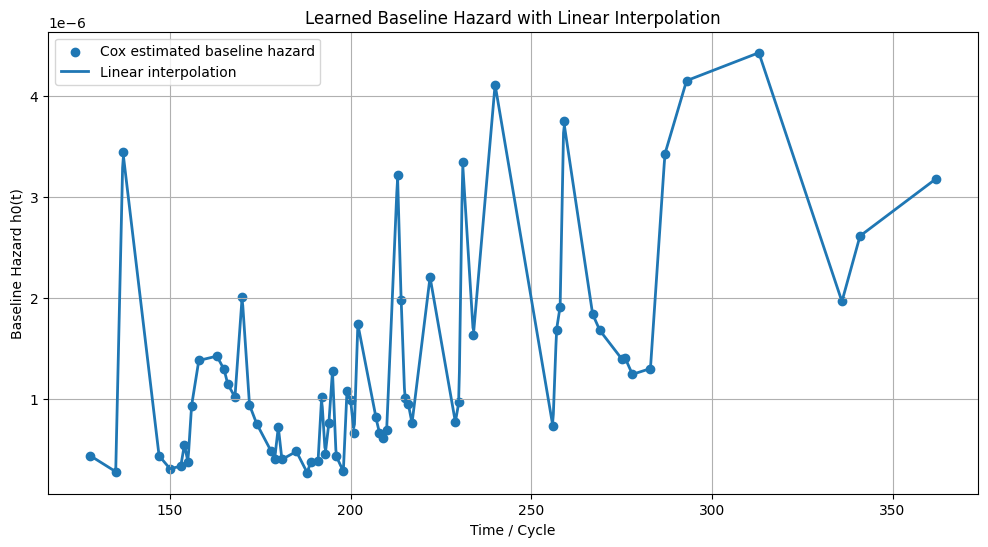

In [ ]:
# ============================================================
# LEARNED BASELINE HAZARD + LINEAR INTERPOLATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Get baseline cumulative hazard from Cox model
# ------------------------------------------------------------
baseline_cum_haz = ctv.baseline_cumulative_hazard_.iloc[:, 0]

# ------------------------------------------------------------
# 2. Convert cumulative hazard H0(t)
#    into baseline hazard h0(t)
# ------------------------------------------------------------
baseline_hazard = baseline_cum_haz.diff().fillna(baseline_cum_haz)

# Make sure everything is numeric
baseline_times = baseline_hazard.index.to_numpy(dtype=float)
baseline_values = baseline_hazard.to_numpy(dtype=float)

# ------------------------------------------------------------
# 3. Remove any duplicated time points
# ------------------------------------------------------------
unique_times, unique_indices = np.unique(
    baseline_times,
    return_index=True
)

unique_values = baseline_values[unique_indices]

baseline_times = unique_times
baseline_values = unique_values

# ------------------------------------------------------------
# 4. Linear interpolation function
# ------------------------------------------------------------
def baseline_hazard_linear(t):

    # Before first observed Cox point
    if t <= baseline_times[0]:
        return baseline_values[0]

    # After last observed Cox point
    if t >= baseline_times[-1]:
        return baseline_values[-1]

    # Find surrounding points
    idx = np.searchsorted(baseline_times, t)

    t1 = baseline_times[idx - 1]
    t2 = baseline_times[idx]

    h1 = baseline_values[idx - 1]
    h2 = baseline_values[idx]

    # Linear interpolation
    h = h1 + (h2 - h1) * (t - t1) / (t2 - t1)

    # Hazard cannot be negative
    return max(h, 0.0)


print("============================================================")
print("LEARNED BASELINE HAZARD")
print("============================================================")
print("First baseline time :", baseline_times[0])
print("Last baseline time  :", baseline_times[-1])
print("Number of points    :", len(baseline_times))

print("\nExample interpolated hazards:")

for t in [
    baseline_times[0],
    (baseline_times[0] + baseline_times[-1]) / 2,
    baseline_times[-1]
]:
    print(
        f"t = {t:.1f}  ->  h0(t) = {baseline_hazard_linear(t):.8f}"
    )


# ------------------------------------------------------------
# 5. Plot learned baseline hazard
# ------------------------------------------------------------
plt.figure(figsize=(12, 6))

plt.scatter(
    baseline_times,
    baseline_values,
    label="Cox estimated baseline hazard"
)

dense_times = np.linspace(
    baseline_times[0],
    baseline_times[-1],
    1000
)

dense_hazards = np.array([
    baseline_hazard_linear(t)
    for t in dense_times
])

plt.plot(
    dense_times,
    dense_hazards,
    linewidth=2,
    label="Linear interpolation"
)

plt.xlabel("Time / Cycle")
plt.ylabel("Baseline Hazard h0(t)")
plt.title("Learned Baseline Hazard with Linear Interpolation")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
print(baseline_cum_haz.tail())

print(baseline_cum_haz.head(10))
print(baseline_cum_haz.index.min())
print(baseline_cum_haz.index.max())

print(cox_df[['start', 'stop', 'Event']].head())
print(cox_df[cox_df['Event'] == 1][['Device_ID', 'start', 'stop']].head())

293    0.000078
313    0.000082
336    0.000084
341    0.000087
362    0.000090
Name: baseline hazard, dtype: float64
128    4.400494e-07
135    7.231361e-07
137    4.171345e-06
147    4.611805e-06
150    4.924124e-06
153    5.260944e-06
154    5.808253e-06
155    6.189030e-06
156    7.125718e-06
158    8.509775e-06
Name: baseline hazard, dtype: float64
128
362
   start  stop  Event
0      0     1      0
1      1     2      0
2      2     3      0
3      3     4      0
4      4     5      0
      Device_ID  start  stop
191           1    191   192
478           2    286   287
657           3    178   179
846           4    188   189
1115          5    268   269


In [ ]:

import os
import pandas as pd
train_min = {}
train_max = {}

for s in selected_sensors:
    train_min[s] = train_df[s].min()
    train_max[s] = train_df[s].max()

    train_df[s] = (
        (train_df[s] - train_min[s]) /
        (train_max[s] - train_min[s])
    )
# Load the live test dataset
test_file_path = os.path.join(project_dir, 'test_FD001.txt')
columns = ['Device_ID', 'Time_Cycle', 'Op_Setting_1', 'Op_Setting_2', 'Op_Setting_3'] + \
          [f'Sensor_{i}' for i in range(1, 22)]

test_df = pd.read_csv(test_file_path, sep=r'\s+', header=None, names=columns)

# Normalize the live test data using the exact same bounds from the training data
for s in selected_sensors:
    test_df[s] = (test_df[s] - train_min[s]) / (train_max[s] - train_min[s])

print("✅ Live Test Data (test_df) successfully loaded and normalized.")

✅ Live Test Data (test_df) successfully loaded and normalized.


In [ ]:
print(test_df.shape)
print(test_df[['Device_ID', 'Time_Cycle', 'Sensor_7', 'Sensor_3']].head())
print(test_df[['Device_ID', 'Time_Cycle', 'Sensor_7', 'Sensor_3']].tail())

(13096, 26)
   Device_ID  Time_Cycle  Sensor_7  Sensor_3
0          1           1    553.90   1585.29
1          1           2    554.85   1588.45
2          1           3    554.11   1586.94
3          1           4    554.07   1584.12
4          1           5    554.16   1587.19
       Device_ID  Time_Cycle  Sensor_7  Sensor_3
13091        100         194    553.41   1599.45
13092        100         195    553.22   1595.69
13093        100         196    553.04   1593.15
13094        100         197    553.37   1594.99
13095        100         198    552.48   1601.62


In [ ]:
import numpy as np
from scipy.stats import multivariate_normal

# =====================================================================
# SECTION 5: ONLINE PARTICLE FILTER (LIVE TRACKING)
# =====================================================================
# Simulating a live engine (e.g., Engine 101) with 100 cycles of data
# live_sensor_data shape: (100, 2) -> [Sensor_7, Sensor_3]
engine_id = 2

engine_df = test_df[test_df['Device_ID'] == engine_id].copy()

live_sensor_data = engine_df[['Sensor_7', 'Sensor_3']].values

N_particles = 1000

# 1. Initialize the Swarm (Cycle 0)
# Draw 1000 random beta vectors from the historical Phase 1 prior
particles_beta = np.random.multivariate_normal(mu_0_p1, Sigma_0_p1, N_particles)

# Initialize uniform weights
weights = np.ones(N_particles) / N_particles

# Lock in our fixed covariance matrix to prevent singularity crashes
fixed_cov = avg_noise_cov_p1

estimated_true_degradation = []

print("Starting Live Particle Filter Tracking...")

# 2. Live Update Loop (Cycle t)
for t, y_t in enumerate(live_sensor_data, start=1):
    X_t = np.array([1, t]) # Linear time matrix

    # Step A: Prediction & Measurement Update
    for i in range(N_particles):
        # Extract individual sensor parameters (Assumes beta is [int_7, slope_7, int_3, slope_3])
        beta_s7 = particles_beta[i][:2]
        beta_s3 = particles_beta[i][2:]

        # Predict the 2D sensor reading
        y_hat = np.array([X_t @ beta_s7, X_t @ beta_s3])

        # Calculate likelihood using the Bivariate Gaussian PDF and fixed covariance
        likelihood = multivariate_normal.pdf(y_t, mean=y_hat, cov=fixed_cov)
        weights[i] *= likelihood

    # Step B: Normalization
    weights += 1e-300 # Tiny constant to prevent divide-by-zero if all predictions are bad
    weights /= np.sum(weights)

    # Step C: State Estimation (Expected Value)
    # The official beta is the weighted average of the swarm
    beta_hat = np.average(particles_beta, axis=0, weights=weights)

    # Calculate the official noise-free degradation point (r_t)
    r_t = np.array([X_t @ beta_hat[:2], X_t @ beta_hat[2:]])
    estimated_true_degradation.append(r_t)

    # Step D: Sequential Importance Resampling (Survival of the Fittest)
    # Clone good particles, delete bad ones based on probability weight
    indices = np.random.choice(np.arange(N_particles), size=N_particles, p=weights, replace=True)
    particles_beta = particles_beta[indices]

    # Step E: Reset Weights
    weights = np.ones(N_particles) / N_particles

print("beta_hat =", beta_hat)
print("last degradation =", estimated_true_degradation[-1])

print("✅ Live tracking complete. Official degradation path calculated.")

Starting Live Particle Filter Tracking...
beta_hat = [ 6.78499385e-01 -7.30956077e-04  3.25680143e-01  6.60200433e-04]
last degradation = [0.64268254 0.35802996]
✅ Live tracking complete. Official degradation path calculated.


In [ ]:
import numpy as np
import os
import pandas as pd

# ==========================================
# 1. FORECAST RUL (SURVIVAL INTEGRATION)
# ==========================================
max_future_cycles = 250
survival_curve = []
cumulative_hazard = 0
current_t = len(live_sensor_data)

for future_t in range(current_t, current_t + max_future_cycles):
    X_future = np.array([1, future_t])

    # Predict future degradation point using the final official beta_hat
    future_r7 = X_future @ beta_hat[:2]
    future_r3 = X_future @ beta_hat[2:]

    current_t = len(live_sensor_data)

    # Calculate instantaneous risk (using assumed baseline hazard 0.001 for demonstration)
    current_risk = 0.001 * np.exp(alpha_s7 * future_r7 + alpha_s3 * future_r3)
    cumulative_hazard += current_risk

    survival_prob = np.exp(-cumulative_hazard)
    survival_curve.append(survival_prob)

    if survival_prob < 0.01:
        break
print("last future cycle:", future_t)
print("last future r7/r3:", future_r7, future_r3)
print("last hazard:", current_risk)
print("last cumulative hazard:", cumulative_hazard)
print("last survival:", survival_prob)
predicted_rul = np.sum(survival_curve)

# ==========================================
# 2. LOAD NASA GROUND TRUTH
# ==========================================
truth_file = os.path.join(project_dir, 'RUL_FD001.txt')
true_rul_df = pd.read_csv(truth_file, sep=r'\s+', header=None, names=['True_RUL'])

# Assuming we are testing Engine 1 (Index 0 in the truth file)
engine_id = 2
actual_rul = true_rul_df.iloc[engine_id - 1]['True_RUL']

# ==========================================
# 3. CALCULATE EVALUATION METRICS
# ==========================================
# Calculate the raw error (d)
d = predicted_rul - actual_rul

# Calculate RMSE (Root Mean Square Error)
rmse = np.sqrt(d**2)

# Calculate Asymmetric Prognostic Score
if d < 0:
    asymmetric_score = np.exp(-d / 13) - 1
else:
    asymmetric_score = np.exp(d / 10) - 1

print(f"--- ENGINE {engine_id} RESULTS ---")
print(f"Predicted RUL: {predicted_rul:.2f} cycles")
print(f"Actual RUL: {actual_rul} cycles")
print(f"Raw Error (d): {d:.2f} cycles")
print(f"RMSE: {rmse:.2f}")
print(f"Asymmetric Score: {asymmetric_score:.2f}")

last future cycle: 298
last future r7/r3: 0.4606744737876759 0.5224198719765276
last hazard: 0.023467040217892754
last cumulative hazard: 0.7224144449379484
last survival: 0.48557843707030796
--- ENGINE 2 RESULTS ---
Predicted RUL: 231.30 cycles
Actual RUL: 98 cycles
Raw Error (d): 133.30 cycles
RMSE: 133.30
Asymmetric Score: 615371.99


In [ ]:
future_t = current_t + 1
X_future = np.array([1, future_t])

future_r7 = X_future @ beta_hat[:2]
future_r3 = X_future @ beta_hat[2:]

eta = alpha_s7 * future_r7 + alpha_s3 * future_r3
hazard = 0.0001 * np.exp(eta)

print("future cycle:", future_t)
print("future r7/r3:", future_r7, future_r3)
print("eta:", eta)
print("hazard:", hazard)

print("last future r7/r3:", future_r7[-1], future_r3[-1])
print("last hazard:", hazards[-1])
print("last survival:", survival_curve[-1])

future cycle: 32
future r7/r3: 0.6464915933077687 0.3541228671110468
eta: -5.249038445508656
hazard: 5.252566600738008e-07


IndexError: invalid index to scalar variable.